> **Antecedente de la versión 1.** El alcance vigente desde el 24/11/2026 es manzana roja, banano y limón. Este cuaderno conserva la preparación anterior con naranjas para trazabilidad. Continuar en el cuaderno 04 y consultar `config/alcance_actual.json`.

# Preparación de imágenes de manzana roja, banano y naranja

**Proyecto estado de frutas · Algoritmos y Programación III**

Continuamos la fase de preparación de datos de CRISP-DM. Partimos del inventario
y las revisiones del cuaderno 01. Comparamos máscaras, aislamos ejemplares y
preparamos características para SVM/Random Forest e imágenes para una CNN.

**Pregunta de esta fase:** ¿podemos separar la fruta del fondo conservando sus
defectos visibles y la geometría necesaria para medir su ocupación en la fotografía?

Las etiquetas buena, intermedia y mala requieren una revisión registrada. Las revisiones del asistente se identifican como tales y admiten una segunda revisión del equipo. Una propuesta
de segmentación tampoco se considera correcta solo porque el algoritmo terminó.
Este cuaderno funciona aunque todavía no haya etiquetas confirmadas: procesa una
muestra de desarrollo y deja explícito qué falta para construir la base de modelado.

## 1. Entorno, parámetros y archivos

Ejecutar de arriba abajo. Se necesitan las dependencias del proyecto, incluyendo
`opencv-python`, `ipywidgets`, `pandas`, `numpy`, `Pillow`, `matplotlib` y `scikit-learn`.
Si faltan en el kernel: `%pip install opencv-python ipywidgets pandas numpy pillow matplotlib scikit-learn ipykernel`.

Las operaciones reutilizables están en `src/data/preparacion_imagenes.py`, con funciones
pequeñas y comentadas. El cuaderno muestra el proceso, las comparaciones y su interpretación.
Los originales no se modifican. Las máscaras y entradas CNN van a `data/processed/`;
las decisiones de revisión se conservan en `data/annotations/`.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, clear_output
from matplotlib_inline.backend_inline import set_matplotlib_formats

SEMILLA = 42
N_POR_GRUPO = 4
PROCESAR_TODO = False  # Activar después de calibrar la segmentación en la muestra.
CALIDADES = ['buena', 'intermedia', 'mala']
candidatas = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'proyecto_estado_frutas']
PROYECTO = next((p for p in candidatas if (p / 'estructura_proyecto.md').is_file()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde el proyecto o desde APOIII.')
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

from src.data.preparacion_imagenes import (
    VERSION, leer_rgb, mascara_otsu, mascara_grabcut, mascara_poligono,
    diagnosticar_mascara, guardar_preparacion, construir_grupos, particionar_por_grupos,
    guardar_tabla, guardar_figura, guardar_bytes_si_cambio,
)

RUTA_DATOS = PROYECTO / 'data/raw/fruit-quality-classification'
ANOTACIONES = PROYECTO / 'data/annotations'
PREPARADAS = PROYECTO / 'data/processed' / VERSION
SALIDAS = PROYECTO / 'experiments/results/preparacion_imagenes'
for carpeta in [ANOTACIONES, PREPARADAS, SALIDAS]:
    carpeta.mkdir(parents=True, exist_ok=True)
ARCHIVO_INVENTARIO = PROYECTO / 'experiments/results/revision_datos/inventario_imagenes.csv'
ARCHIVO_CALIDAD = ANOTACIONES / 'revision_equipo.csv'
ARCHIVO_MASCARAS = ANOTACIONES / 'revision_mascaras.csv'
ARCHIVO_EJEMPLARES = ANOTACIONES / 'ejemplares_segmentados.csv'
ARCHIVO_EXPLORACION = ANOTACIONES / 'historial_exploracion.csv'

cv2.setNumThreads(1)
plt.rcParams.update({'figure.dpi': 90, 'font.size': 10})
set_matplotlib_formats('jpeg')
print('OpenCV:', cv2.__version__, '| Versión de preparación:', VERSION)

OpenCV: 5.1.0 | Versión de preparación: preparacion_v1


## 2. Leer inventario y decisiones vigentes

Leemos directamente `revision_equipo.csv`, sin depender de que la exportación del
cuaderno 01 se haya actualizado. Una etiqueta se utiliza solamente si el revisor registrado
incluyó el ejemplar, confirmó calidad e individualidad y, en manzanas, el alcance rojo.
También comprobamos que la revisión corresponda a la huella del inventario.

Los recortes individuales que se creen más adelante conservan el identificador y
la huella de la fotografía original. Distintos recortes de una misma fotografía
deberán permanecer juntos al dividir los datos.

In [2]:
def leer_csv_opcional(ruta, columnas):
    if ruta.is_file():
        tabla = pd.read_csv(ruta, dtype=str, keep_default_na=False)
        faltantes = set(columnas) - set(tabla.columns)
        if faltantes:
            raise ValueError(f'Faltan columnas en {ruta.name}: {sorted(faltantes)}')
        return tabla
    return pd.DataFrame(columns=columnas)

if not ARCHIVO_INVENTARIO.is_file():
    raise FileNotFoundError('Ejecutar primero el inventario del cuaderno 01.')
inventario = pd.read_csv(ARCHIVO_INVENTARIO, keep_default_na=False)
assert inventario['id_imagen'].is_unique
inventario = inventario.loc[inventario['archivo_legible'].astype(str).str.lower().eq('true')].copy()
COL_CALIDAD = ['id_imagen', 'sha256', 'calidad_revisada', 'decision', 'manzana_roja',
               'ejemplar_individual', 'grupo_ejemplar', 'revisor']
COL_EJEMPLARES = ['id_ejemplar', 'id_origen', 'sha_original', 'fruta', 'ruta_relativa',
                  'calidad_revisada', 'manzana_roja', 'ejemplar_individual',
                  'grupo_ejemplar', 'revisor', 'observaciones', 'fecha_revision_utc']

def cargar_catalogo():
    revisiones = leer_csv_opcional(ARCHIVO_CALIDAD, COL_CALIDAD)
    if not revisiones['id_imagen'].is_unique:
        raise ValueError('Hay identificadores repetidos en las revisiones de calidad.')
    base = inventario.merge(revisiones, on='id_imagen', how='left', validate='one_to_one',
                            suffixes=('', '_revision'))
    for campo in COL_CALIDAD:
        if campo not in ['id_imagen', 'sha256']:
            base[campo] = base[campo].fillna('')
    base['etiqueta_confirmada'] = (base['decision'].eq('incluir') &
        base['calidad_revisada'].isin(CALIDADES) & base['ejemplar_individual'].eq('si') &
        (base['fruta'].ne('manzana') | base['manzana_roja'].eq('si')) &
        base['sha256'].eq(base['sha256_revision']) & base['revisor'].str.strip().ne(''))
    base['id_ejemplar'] = base['id_imagen']
    base['id_origen'] = base['id_imagen']
    base['sha_original'] = base['sha256']
    base['es_recorte_individual'] = False
    hijos = leer_csv_opcional(ARCHIVO_EJEMPLARES, COL_EJEMPLARES)
    if not hijos['id_ejemplar'].is_unique:
        raise ValueError('Hay identificadores de recorte repetidos.')
    if not hijos.empty:
        origen = inventario.set_index('id_imagen')
        for fila in hijos.itertuples():
            if fila.id_origen not in origen.index or fila.sha_original != origen.loc[fila.id_origen, 'sha256']:
                raise ValueError('Un recorte no coincide con la fotografía de origen del inventario.')
            if fila.fruta != origen.loc[fila.id_origen, 'fruta'] or fila.ruta_relativa != origen.loc[fila.id_origen, 'ruta_relativa']:
                raise ValueError('Los metadatos de un recorte no coinciden con su fotografía de origen.')
        hijos['etiqueta_confirmada'] = (hijos['calidad_revisada'].isin(CALIDADES) &
            hijos['ejemplar_individual'].eq('si') & hijos['revisor'].str.strip().ne('') &
            (hijos['fruta'].ne('manzana') | hijos['manzana_roja'].eq('si')))
        hijos['es_recorte_individual'] = True
        base = pd.concat([base, hijos], ignore_index=True, sort=False)
    assert base['id_ejemplar'].is_unique
    return base

catalogo = cargar_catalogo()
display(catalogo.groupby('fruta').agg(imagenes_o_ejemplares=('id_ejemplar', 'size'),
                                     etiquetas_confirmadas=('etiqueta_confirmada', 'sum')))
print('Memoria del catálogo (MB):', round(catalogo.memory_usage(deep=True).sum() / 1e6, 2))

,imagenes_o_ejemplares,etiquetas_confirmadas
fruta,,
banano,2489,13
manzana,2403,12
naranja,2500,28


Memoria del catálogo (MB): 4.13


## 3. Muestra de desarrollo y trazabilidad de la exploración

Usamos cuatro imágenes por fruta y etiqueta original, añadimos las 50 propuestas
del cuaderno 01 y todos los originales con etiqueta confirmada. La muestra no certifica
que una manzana sea roja ni que una fotografía contenga un solo fruto.

El historial registra las fotografías exploradas, incluidas las galerías del cuaderno 01.
Sus grupos se reservarán para entrenamiento/desarrollo. No se usarán esas mismas fotos
como una prueba final independiente después de ajustar el procesamiento sobre ellas.
`PROCESAR_TODO=True` procesa todo el inventario y lo marca como explorado; no utilizarlo
si se quiere reservar una evaluación con fotografías públicas todavía no inspeccionadas.

In [3]:
originales = catalogo.loc[~catalogo['es_recorte_individual']].copy()
seleccion = (originales.groupby(['fruta', 'calidad_original'], group_keys=False)
             .sample(n=N_POR_GRUPO, random_state=SEMILLA)['id_ejemplar'].tolist())
propuestas = pd.read_csv(ANOTACIONES / 'propuestas_revision_inicial.csv', keep_default_na=False)
seleccion += originales.loc[originales['ruta_relativa'].isin(propuestas['ruta_relativa']), 'id_ejemplar'].tolist()
seleccion += originales.loc[originales['etiqueta_confirmada'], 'id_ejemplar'].tolist()
piloto = originales.copy() if PROCESAR_TODO else originales.loc[originales['id_ejemplar'].isin(seleccion)].copy()
piloto = piloto.sort_values('id_ejemplar').reset_index(drop=True)

COL_EXPLORACION = ['id_origen']
def registrar_exploracion(ids):
    anterior = leer_csv_opcional(ARCHIVO_EXPLORACION, COL_EXPLORACION)
    nueva = pd.DataFrame({'id_origen': list(ids)})
    historial = pd.concat([anterior, nueva], ignore_index=True).drop_duplicates('id_origen')
    if set(nueva['id_origen']) - set(anterior['id_origen']):
        (SALIDAS / 'particiones.csv').unlink(missing_ok=True)
    guardar_tabla(historial.sort_values('id_origen'), ARCHIVO_EXPLORACION)
    return set(historial['id_origen'])

ids_vistos = set(piloto['id_origen'])
galeria_anterior = PROYECTO / 'experiments/results/revision_datos/muestra_visual.csv'
if galeria_anterior.is_file():
    ids_vistos.update(pd.read_csv(galeria_anterior)['id_imagen'])
ids_vistos.update(originales.loc[originales['ruta_relativa'].isin(propuestas['ruta_relativa']), 'id_origen'])
origenes_explorados = registrar_exploracion(ids_vistos)
guardar_tabla(piloto[['id_ejemplar', 'id_origen', 'fruta', 'calidad_original', 'ruta_relativa']],
              SALIDAS / 'muestra_desarrollo.csv')
print('Fotografías en el piloto:', len(piloto))
display(pd.crosstab(piloto['fruta'], piloto['calidad_original']))

Fotografías en el piloto: 97


calidad_original,buena,mala,sin_etiqueta
fruta,,,
banano,12,12,4
manzana,13,14,4
naranja,18,16,4


## 4. Dos propuestas de máscara

**Otsu** separa intensidades claras y oscuras; elegimos como fondo la polaridad
predominante en el borde. **GrabCut** parte de un rectángulo que debe encerrar la fruta.
Ninguno reconoce semánticamente una fruta: pueden incluir manos, quitar lesiones o
seleccionar parte del fondo. Por eso se comparan visualmente y requieren revisión.

Conservamos el componente mayor y rellenamos huecos internos para evitar eliminar
automáticamente una lesión oscura. Esto también puede unir regiones incorrectas:
rellenar huecos no demuestra que la máscara sea correcta.

Referencias: [OpenCV, Otsu](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html)
y [OpenCV, GrabCut](https://docs.opencv.org/4.x/d8/d83/tutorial_py_grabcut.html).

In [4]:
def recuperar_preparacion_vigente(fila, metodo):
    archivo = PREPARADAS / fila.id_ejemplar / metodo / 'preparacion.json'
    if not archivo.is_file():
        return None
    datos = json.loads(archivo.read_text(encoding='utf-8'))
    if (datos.get('version') != VERSION or datos.get('opencv') != cv2.__version__ or
        datos.get('sha_original') != fila.sha_original or datos.get('parametros') != {}):
        return None
    for nombre, huella in [('ruta_mascara', 'sha_mascara'), ('ruta_cnn', 'sha_cnn')]:
        ruta = Path(datos[nombre])
        if not ruta.is_file() or hashlib.sha256(ruta.read_bytes()).hexdigest() != datos[huella]:
            return None
    return datos

resultados, errores = [], []
reutilizadas = 0
for numero, fila in enumerate(piloto.itertuples(), 1):
    ruta = RUTA_DATOS / fila.ruta_relativa
    if hashlib.sha256(ruta.read_bytes()).hexdigest() != fila.sha_original:
        raise ValueError(f'Cambió el archivo {fila.id_ejemplar}; repetir el inventario.')
    rgb = leer_rgb(ruta)
    for metodo, funcion in [('otsu', mascara_otsu), ('grabcut', mascara_grabcut)]:
        try:
            datos = recuperar_preparacion_vigente(fila, metodo)
            if datos is None:
                mascara = funcion(rgb)
                datos = guardar_preparacion(rgb, mascara, PREPARADAS, fila.id_ejemplar,
                                           fila.sha_original, metodo)
            else:
                reutilizadas += 1
            resultados.append(datos)
        except (ValueError, cv2.error) as error:
            errores.append({'id_ejemplar': fila.id_ejemplar, 'metodo': metodo, 'error': str(error)})
    if numero % 20 == 0:
        print(f'Procesadas {numero}/{len(piloto)} fotografías')

# Recuperar máscaras aceptadas desde las anotaciones, incluso si se borró data/processed.
if ARCHIVO_MASCARAS.is_file():
    revisadas = pd.read_csv(ARCHIVO_MASCARAS, dtype=str, keep_default_na=False)
    por_id = catalogo.set_index('id_ejemplar')
    for fila in revisadas.loc[revisadas['decision_mascara'].eq('aceptada')].itertuples():
        carpeta = ANOTACIONES / 'mascaras_revisadas' / fila.id_ejemplar / fila.sha_mascara
        receta = carpeta / 'receta.json'
        if fila.id_ejemplar not in por_id.index or not receta.is_file():
            continue
        origen = por_id.loc[fila.id_ejemplar]
        if fila.sha_original != origen['sha_original']:
            continue
        rgb = leer_rgb(RUTA_DATOS / origen['ruta_relativa'])
        actual = hashlib.sha256((RUTA_DATOS / origen['ruta_relativa']).read_bytes()).hexdigest()
        if actual != fila.sha_original:
            raise ValueError('Cambió un original de una máscara revisada; actualizar inventario.')
        configuracion = json.loads(receta.read_text(encoding='utf-8'))
        mascara = (np.asarray(Image.open(carpeta / 'mascara.png')) > 0).astype(np.uint8)
        guardar_preparacion(rgb, mascara, PREPARADAS, fila.id_ejemplar, fila.sha_original,
                            fila.metodo, configuracion['parametros'])

def cargar_preparaciones():
    filas = [json.loads(p.read_text(encoding='utf-8')) for p in PREPARADAS.glob('*/*/preparacion.json')]
    tabla = pd.DataFrame(filas)
    if not tabla.empty:
        assert not tabla.duplicated(['id_ejemplar', 'metodo']).any()
    return tabla

preparaciones = cargar_preparaciones()
guardar_tabla(pd.DataFrame(errores, columns=['id_ejemplar', 'metodo', 'error']),
              SALIDAS / 'errores_segmentacion.csv')
print('Propuestas de máscara calculadas:', len(resultados), '| Intentos sin resultado:', len(errores))
print('Resultados vigentes reutilizados:', reutilizadas)

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\juanp\\Documents\\Algoritmos&ProgramacionIII\\proyecto_estado_frutas\\data\\raw\\fruit-quality-classification\\Good Quality_Fruits\\Orange_Good\\IMG_1907.JPG'

,propuestas,ocupacion_mediana,alertas
metodo,,,
grabcut,96,0.280,0
otsu,97,0.312,86
poligono_piloto,3,0.135,0
revision_asistente_v1,102,0.092,13
revision_asistente_v2,102,0.145,9
revision_asistente_v3,102,0.137,9
revision_asistente_v4,102,0.136,9
revision_asistente_v5,102,0.136,9


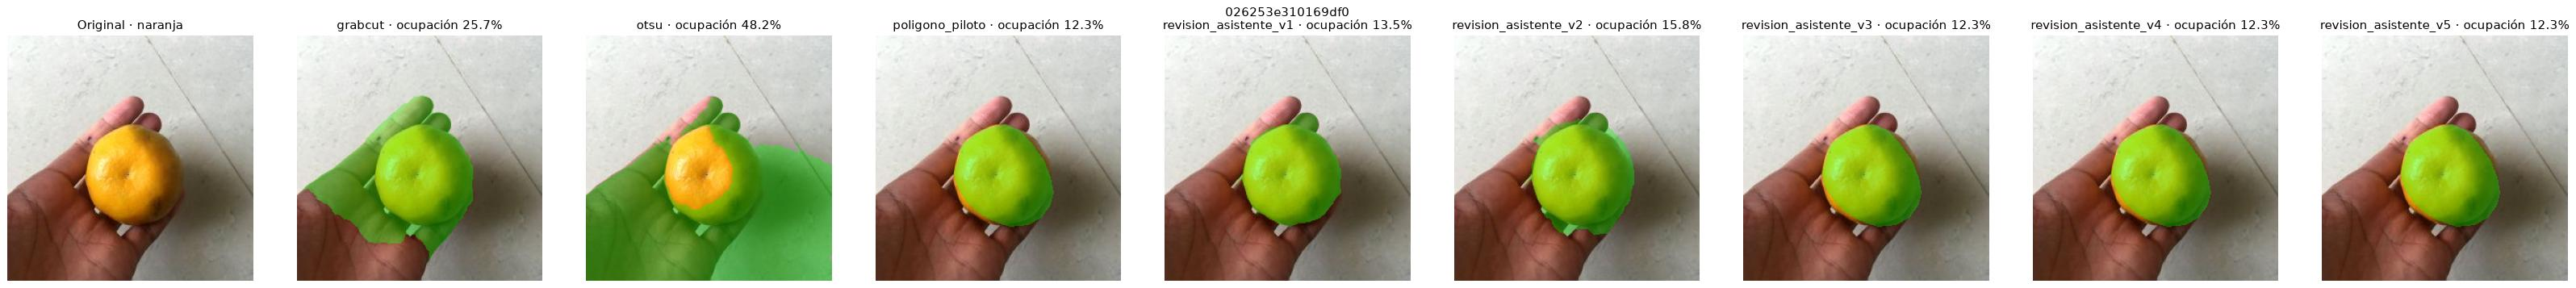

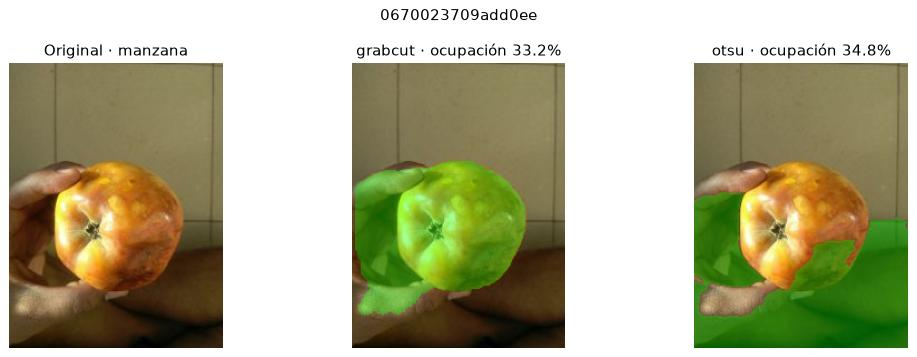

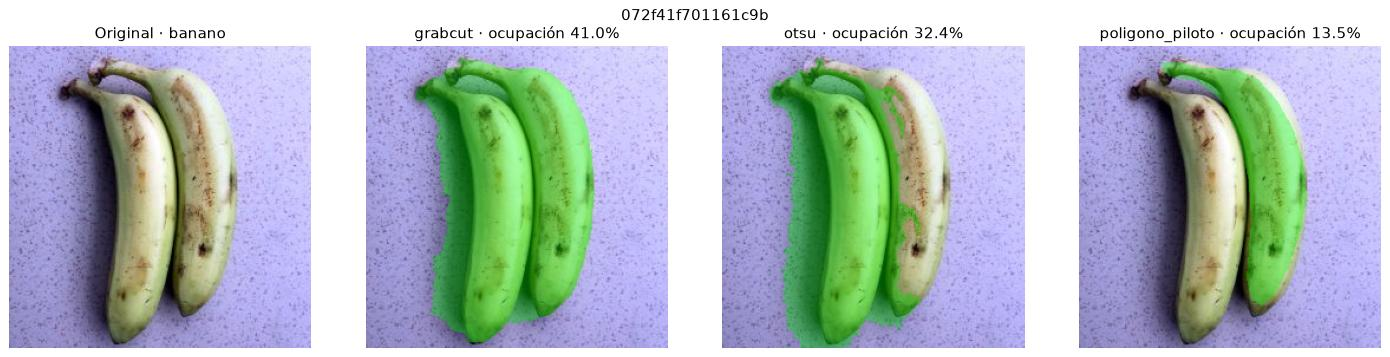

In [ ]:
resumen_mascaras = preparaciones.groupby('metodo').agg(
    propuestas=('id_ejemplar', 'size'), ocupacion_mediana=('ocupacion', 'median'),
    alertas=('alertas_mascara', lambda valores: valores.ne('').sum()))
display(resumen_mascaras.round(3))

def mostrar_comparacion(id_ejemplar):
    fila = cargar_catalogo().set_index('id_ejemplar').loc[id_ejemplar]
    rgb = leer_rgb(RUTA_DATOS / fila['ruta_relativa'])
    candidatas = cargar_preparaciones()
    candidatas = candidatas.loc[candidatas['id_ejemplar'].eq(id_ejemplar)]
    fig, ejes = plt.subplots(1, len(candidatas)+1, figsize=(4*(len(candidatas)+1), 4))
    ejes = np.atleast_1d(ejes)
    ejes[0].imshow(rgb)
    ejes[0].set_title(f"Original · {fila['fruta']}")
    for eje, datos in zip(ejes[1:], candidatas.itertuples()):
        mascara = np.asarray(Image.open(datos.ruta_mascara)) > 0
        superpuesta = rgb.copy()
        superpuesta[mascara] = (0.65*rgb[mascara] + 0.35*np.array([0, 255, 0])).astype(np.uint8)
        eje.imshow(superpuesta)
        eje.set_title(f'{datos.metodo} · ocupación {datos.ocupacion:.1%}')
    for eje in ejes:
        eje.axis('off')
    fig.suptitle(id_ejemplar)
    fig.tight_layout()
    return fig

ejemplos = piloto.groupby('fruta', group_keys=False).head(1)
for fila in ejemplos.itertuples():
    figura = mostrar_comparacion(fila.id_ejemplar)
    guardar_figura(figura, SALIDAS / f'comparacion_{fila.fruta}.jpg', dpi=100)
    plt.show()

### Qué significan las alertas

Una ocupación menor del 3 %, mayor del 85 % o una máscara que toca el borde
activa una alerta geométrica. Son umbrales de revisión iniciales, no métricas de
exactitud de segmentación. Una máscara sin alertas puede seguir incluyendo una mano
o excluir parte de la fruta. Sin máscaras de referencia no calculamos IoU ni Dice.

Hay que revisar que el contorno incluya la fruta completa y sus defectos, y excluya
manos, sombras y otros frutos. Se puede rechazar una propuesta aunque no tenga alertas.

## 5. Recorte para CNN y medición antes de recortar

La entrada CNN es RGB de **224 × 224**, con proporciones conservadas y relleno gris.
Se conserva como `uint8`; al alimentar la futura red se convertirá a `float32 / 255`.
No se aplica aumento de datos a validación o prueba ni se decide aquí una arquitectura.

La ocupación se calcula en la máscara con las dimensiones de la fotografía original:

$$r_A = \frac{\sum_{x,y} M(x,y)}{H\,W}.$$

El diámetro equivalente es el de un círculo con igual área, normalizado por el lado
menor de la fotografía. En banano no equivale a su longitud. Estas mediciones describen
la proyección visible, no centímetros ni tamaño físico comparable entre fotos públicas.
Los límites pequeño/mediano/grande quedan para capturas con encuadre controlado.

El primer ejemplo muestra una propuesta automática, que puede incluir parte de una mano.
Después se muestran tres propuestas de contorno manual para comparar una manzana roja,
un banano aislado del racimo y una naranja. Son demostraciones para revisar, no máscaras
de referencia ni aprobaciones del equipo.

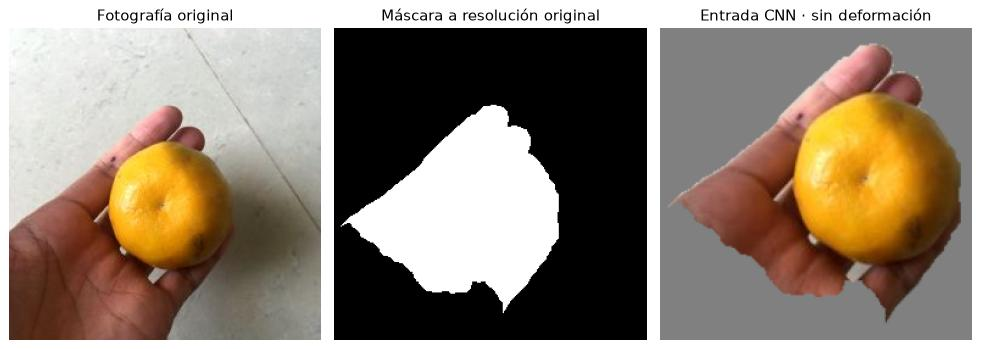

Ocupación propuesta: 25.71%
Rango que recibirá la CNN: 0.0 1.0


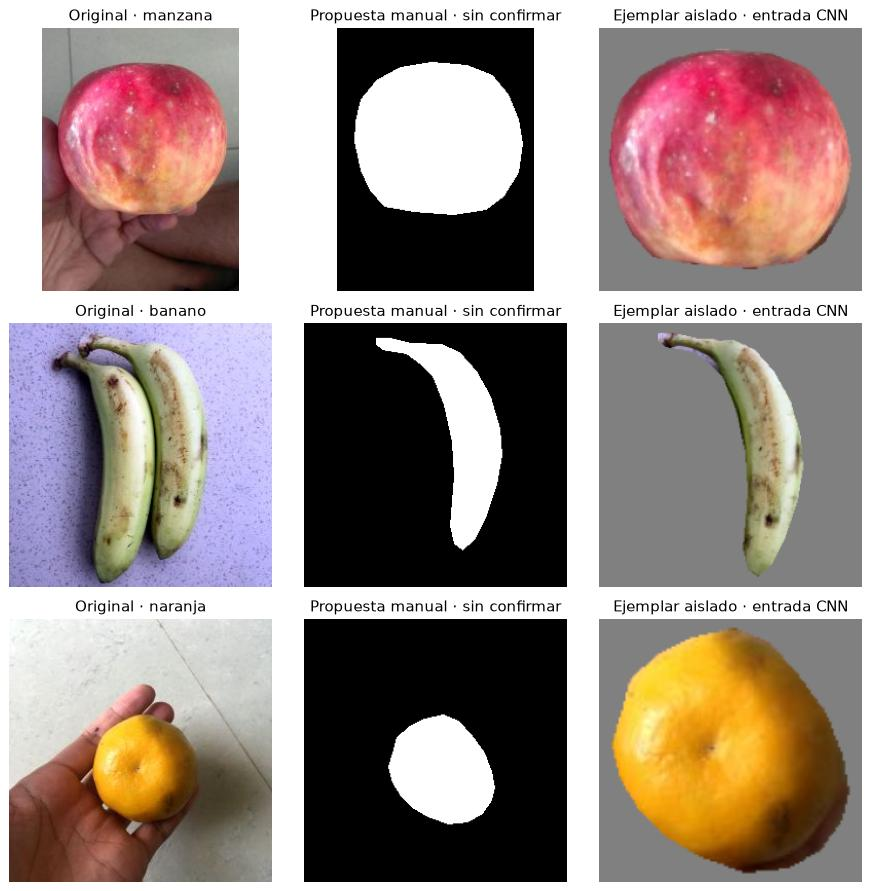

In [ ]:
ejemplo = preparaciones.loc[preparaciones['metodo'].eq('grabcut')].iloc[0]
fila = catalogo.set_index('id_ejemplar').loc[ejemplo['id_ejemplar']]
rgb = leer_rgb(RUTA_DATOS / fila['ruta_relativa'])
mascara = np.asarray(Image.open(ejemplo['ruta_mascara'])) > 0
entrada_cnn = np.asarray(Image.open(ejemplo['ruta_cnn']))
assert mascara.shape == rgb.shape[:2]
assert entrada_cnn.shape == (224, 224, 3)
assert entrada_cnn.dtype == np.uint8

fig, ejes = plt.subplots(1, 3, figsize=(11, 4))
for eje, imagen, titulo in zip(ejes, [rgb, mascara, entrada_cnn],
    ['Fotografía original', 'Máscara a resolución original', 'Entrada CNN · sin deformación']):
    eje.imshow(imagen, cmap='gray' if imagen.ndim == 2 else None)
    eje.set_title(titulo)
    eje.axis('off')
fig.tight_layout()
guardar_figura(fig, SALIDAS / 'ejemplo_preparacion_cnn.jpg', dpi=100)
plt.show()
print('Ocupación propuesta:', f"{mascara.mean():.2%}")
print('Rango que recibirá la CNN:', (entrada_cnn.astype(np.float32)/255).min(),
      (entrada_cnn.astype(np.float32)/255).max())

ejemplos_manuales = json.loads((ANOTACIONES / 'propuestas_mascara_piloto.json').read_text(encoding='utf-8'))['ejemplos']
figura, ejes = plt.subplots(len(ejemplos_manuales), 3, figsize=(10, 10))
for ejes_fila, ejemplo_manual in zip(ejes, ejemplos_manuales):
    fila = originales.set_index('id_ejemplar').loc[ejemplo_manual['id_origen']]
    rgb = leer_rgb(RUTA_DATOS / fila['ruta_relativa'])
    mascara = mascara_poligono(rgb, ejemplo_manual['puntos'])
    datos = guardar_preparacion(rgb, mascara, PREPARADAS, fila.name, fila['sha_original'],
        'poligono_piloto', {'poligono': ejemplo_manual['puntos']})
    ejes_fila[0].imshow(rgb)
    ejes_fila[0].set_title(f"Original · {fila['fruta']}")
    ejes_fila[1].imshow(mascara, cmap='gray')
    ejes_fila[1].set_title('Propuesta manual · sin confirmar')
    ejes_fila[2].imshow(Image.open(datos['ruta_cnn']))
    ejes_fila[2].set_title('Ejemplar aislado · entrada CNN')
    for eje in ejes_fila:
        eje.axis('off')
figura.tight_layout()
guardar_figura(figura, SALIDAS / 'ejemplos_ajuste_manual.jpg', dpi=110)
plt.show()
registrar_exploracion(e['id_origen'] for e in ejemplos_manuales)
preparaciones = cargar_preparaciones()

## 6. Características para los modelos tradicionales

Extraemos estadísticas RGB, histogramas HSV y medias/desviaciones de saturación y valor.
El tono se representa también con seno y coseno porque es circular. La textura usa
coocurrencias de 16 niveles con vecinos horizontales y verticales, solo dentro de la
máscara: contraste, homogeneidad, energía y entropía. La forma incluye circularidad,
solidez y relación de aspecto del rectángulo delimitador.

No convertimos un porcentaje de color oscuro en una etiqueta de calidad. La iluminación,
el moteado natural y los errores de máscara también afectan esas mediciones.
Las variables `tam_` se conservan para estudiar ocupación, separadas de las columnas
`color_`, `textura_` y `forma_` destinadas inicialmente a clasificación.

La normalización de píxeles por 255 es fija. Estandarización, selección de características
y cualquier transformación que aprenda parámetros se ajustarán después, dentro del
Pipeline y únicamente con los datos de entrenamiento de cada fold.

In [ ]:
columnas_modelo = [c for c in preparaciones if c.startswith(('color_', 'textura_', 'forma_'))]
columnas_tamano = [c for c in preparaciones if c.startswith('tam_')]
assert np.isfinite(preparaciones[columnas_modelo + columnas_tamano].to_numpy()).all()
caracteristicas_exploratorias = preparaciones[
    ['id_ejemplar', 'metodo', 'firma_preparacion'] + columnas_modelo + columnas_tamano].copy()
guardar_tabla(caracteristicas_exploratorias, SALIDAS / 'caracteristicas_exploratorias.csv')
print('Características para clasificación:', len(columnas_modelo))
print('Mediciones de ocupación:', columnas_tamano)
display(caracteristicas_exploratorias.head(4))

Características para clasificación: 43
Mediciones de ocupación: ['tam_ocupacion_imagen', 'tam_diametro_equivalente_normalizado']


,id_ejemplar,metodo,firma_preparacion,color_r_media,color_r_desv,color_g_media,color_g_desv,color_b_media,color_b_desv,color_h_seno,...,color_v_desv,textura_contraste,textura_homogeneidad,textura_energia,textura_entropia,forma_circularidad,forma_solidez,forma_aspecto,tam_ocupacion_imagen,tam_diametro_equivalente_normalizado
0,026253e310169df0,grabcut,b241acb3b4b4114fc90101e93bcdd3c1d0bbbc54728b3b...,0.643355,0.253179,0.421952,0.229183,0.184349,0.175659,0.413657,...,0.253179,0.002386,0.860808,0.050446,4.881573,0.611469,0.911618,1.046784,0.257126,0.572174
1,026253e310169df0,otsu,3c38a67e54ab6fe15d645405577d03eebb84d9636160db...,0.455848,0.129280,0.325335,0.132599,0.240319,0.154139,0.461660,...,0.129310,0.001325,0.910359,0.105696,3.806045,0.326546,0.823314,1.333333,0.482254,0.783597
2,026253e310169df0,poligono_piloto,50b1ca2c65b5c3409d5b129efb4b2a20db19d1d095b3cc...,0.750088,0.269468,0.523061,0.234782,0.105243,0.110111,0.601287,...,0.269468,0.000986,0.893001,0.059749,4.564399,0.858617,0.987854,1.028846,0.123199,0.396059
3,026253e310169df0,revision_asistente_v1,feed868d89279baa9746c9ae94826ab68f098c85867403...,0.747098,0.252508,0.519236,0.221733,0.118058,0.115943,0.587062,...,0.252508,0.001625,0.870970,0.055311,4.711663,0.667919,0.938507,1.072072,0.134995,0.414585


## 7. Guardar la revisión de una máscara y aislar ejemplares

Se guarda la huella de la máscara y su configuración. Cambiar la imagen, la máscara
o el procesamiento invalida una aprobación anterior. Confirmar una máscara no confirma
automáticamente la calidad del fruto.

Para fotos con varios frutos se puede delimitar un ejemplar y guardarlo con otro
identificador, conservando la foto de origen. La etiqueta de calidad de ese recorte se
anota individualmente; no se hereda la etiqueta buena/mala del grupo fotografiado.

In [ ]:
COL_MASCARAS = ['id_ejemplar', 'metodo', 'sha_original', 'sha_mascara', 'firma_preparacion',
                 'decision_mascara', 'observaciones', 'revisor', 'fecha_revision_utc']

def actualizar_fila_csv(ruta, nueva, clave, columnas):
    anterior = leer_csv_opcional(ruta, columnas)
    if not anterior[clave].is_unique:
        raise ValueError(f'Hay identificadores repetidos en {ruta.name}.')
    anterior = anterior.loc[anterior[clave].ne(nueva[clave])]
    completa = pd.concat([anterior, pd.DataFrame([nueva])], ignore_index=True)
    temporal = ruta.with_suffix('.tmp')
    completa[columnas].to_csv(temporal, index=False, encoding='utf-8-sig')
    temporal.replace(ruta)

def guardar_revision_mascara(datos, decision, observaciones, revisor):
    if decision not in ['aceptada', 'rechazada'] or not revisor.strip():
        raise ValueError('Indicar decisión y nombre del revisor.')
    if not observaciones.strip():
        raise ValueError('Anotar qué se comprobó o qué falla en la máscara.')
    ruta = Path(datos['ruta_mascara'])
    if hashlib.sha256(ruta.read_bytes()).hexdigest() != datos['sha_mascara']:
        raise ValueError('La máscara cambió; volver a cargarla antes de confirmar.')
    fila_origen = cargar_catalogo().set_index('id_ejemplar').loc[datos['id_ejemplar']]
    if hashlib.sha256((RUTA_DATOS / fila_origen['ruta_relativa']).read_bytes()).hexdigest() != datos['sha_original']:
        raise ValueError('El original cambió; repetir inventario y preparación.')
    fila = {c: datos[c] for c in ['id_ejemplar', 'metodo', 'sha_original', 'sha_mascara', 'firma_preparacion']}
    fila.update(decision_mascara=decision, observaciones=observaciones.strip(),
                revisor=revisor.strip(), fecha_revision_utc=datetime.now(timezone.utc).isoformat())
    if decision == 'aceptada':
        anotada = ANOTACIONES / 'mascaras_revisadas' / datos['id_ejemplar'] / datos['sha_mascara']
        anotada.mkdir(parents=True, exist_ok=True)
        guardar_bytes_si_cambio(anotada / 'mascara.png', ruta.read_bytes())
        guardar_bytes_si_cambio(anotada / 'receta.json', json.dumps(datos, indent=2).encode('utf-8'))
    actualizar_fila_csv(ARCHIVO_MASCARAS, fila, 'id_ejemplar', COL_MASCARAS)
    for nombre in ['base_preparada.csv', 'particiones.csv']:
        (SALIDAS / nombre).unlink(missing_ok=True)

def guardar_ejemplar_individual(id_origen, rgb, mascara, calidad, roja, grupo, notas, revisor):
    if calidad not in ['', *CALIDADES] or not revisor.strip() or not notas.strip():
        raise ValueError('Indicar revisor, evidencia y una calidad válida o dejarla pendiente.')
    padre = originales.set_index('id_origen').loc[id_origen]
    if calidad and padre['fruta'] == 'manzana' and roja != 'si':
        raise ValueError('Para confirmar calidad de una manzana debe confirmarse el alcance rojo.')
    huella = hashlib.sha256((RUTA_DATOS / padre['ruta_relativa']).read_bytes()).hexdigest()
    if huella != padre['sha_original']:
        raise ValueError('Cambió el original; repetir inventario y procesamiento.')
    # La geometría de la máscara identifica el recorte, no un número de orden mutable.
    sufijo = hashlib.sha256(mascara.astype(np.uint8).tobytes()).hexdigest()[:12]
    id_hijo = f'{id_origen}_e_{sufijo}'
    datos = guardar_preparacion(rgb, mascara, PREPARADAS, id_hijo, huella,
                                'ejemplar_manual', {'id_origen': id_origen})
    nueva = dict(zip(COL_EJEMPLARES, [id_hijo, id_origen, huella, padre['fruta'],
        padre['ruta_relativa'], calidad, roja if padre['fruta'] == 'manzana' else 'no_aplica',
        'si', grupo.strip(), revisor.strip(), notas.strip(), datetime.now(timezone.utc).isoformat()]))
    actualizar_fila_csv(ARCHIVO_EJEMPLARES, nueva, 'id_ejemplar', COL_EJEMPLARES)
    guardar_revision_mascara(datos, 'aceptada', notas, revisor)
    registrar_exploracion([id_origen])
    return id_hijo

## 8. Revisor visual y ajustes manuales

Elegir un original del piloto y comparar Otsu/GrabCut. Se puede ajustar el rectángulo
con los controles X/Y y pulsar **Probar región**, o introducir un polígono en coordenadas
entre 0 y 1 y pulsar **Probar polígono**. El origen (0,0) está arriba a la izquierda.
Un ejemplo de formato es `[[0.2,0.2],[0.8,0.2],[0.8,0.8],[0.2,0.8]]`; sus valores
deben adaptarse al contorno real, no copiarse sin revisar.

- **Aceptar máscara:** confirma que la máscara seleccionada representa el ejemplar
  completo del original. Revisar su calidad y alcance en el cuaderno 01.
- **Guardar ejemplar aislado:** usar cuando la selección corresponde a un fruto de
  una fotografía con varios. Revisar el contorno, indicar su calidad o dejarla pendiente,
  y confirmar el alcance rojo si es manzana. Para otra fruta de esa foto, cambiar la región.
- Escribir un grupo compartido para vistas del mismo fruto; evitar reutilizar códigos
  para frutos distintos. Este campo no se puede inferir con seguridad del nombre del archivo.

Los métodos automáticos por sí solos no separan correctamente todos los racimos ni
resuelven oclusiones. Si un ejemplar está muy tapado, conviene excluirlo o recolectar otra foto.

In [ ]:
import ipywidgets as widgets

selector = widgets.Dropdown(options=[(f'{r.fruta} | {r.calidad_original} | {r.id_ejemplar}',
    r.id_ejemplar) for r in piloto.itertuples()], description='Imagen:', layout=widgets.Layout(width='95%'))
metodos_disponibles = sorted(cargar_preparaciones()['metodo'].unique())
metodo_widget = widgets.Dropdown(options=metodos_disponibles, value=('revision_asistente_v5' if 'revision_asistente_v5' in metodos_disponibles else 'grabcut'), description='Máscara:')
x_widget = widgets.FloatRangeSlider(value=[0.02, 0.98], min=0, max=1, step=0.01, description='Rango X:')
y_widget = widgets.FloatRangeSlider(value=[0.02, 0.98], min=0, max=1, step=0.01, description='Rango Y:')
puntos_widget = widgets.Textarea(description='Polígono:', placeholder='[[x1,y1],[x2,y2],[x3,y3],...]',
                                layout=widgets.Layout(width='95%'))
calidad_widget = widgets.Dropdown(options=[('Pendiente', ''), *[(c, c) for c in CALIDADES]], description='Calidad:')
roja_widget = widgets.Dropdown(options=['pendiente', 'si', 'no', 'no_aplica'], description='¿Roja?:')
grupo_widget = widgets.Text(description='Grupo fruto:', placeholder='Código compartido entre vistas del mismo fruto')
revisor_widget = widgets.Text(value='Equipo', description='Revisor:')
notas_widget = widgets.Textarea(description='Evidencia:', layout=widgets.Layout(width='95%'))
region_boton = widgets.Button(description='Probar región')
poligono_boton = widgets.Button(description='Probar polígono')
aceptar_boton = widgets.Button(description='Aceptar máscara', button_style='success')
rechazar_boton = widgets.Button(description='Rechazar máscara')
ejemplar_boton = widgets.Button(description='Guardar ejemplar aislado', button_style='info')
vista, mensaje = widgets.Output(), widgets.Output()
estado = {}

def mostrar_candidata():
    with vista:
        clear_output(wait=True)
        rgb, mascara = estado['rgb'], estado['mascara']
        figura, ejes = plt.subplots(1, 3, figsize=(12, 4))
        ejes[0].imshow(rgb, extent=[0, 1, 1, 0])
        ejes[0].set_title('Original · coordenadas normalizadas')
        ejes[0].set_xticks(np.linspace(0, 1, 6))
        ejes[0].set_yticks(np.linspace(0, 1, 6))
        superpuesta = rgb.copy()
        dentro = mascara > 0
        superpuesta[dentro] = (0.65*rgb[dentro] + 0.35*np.array([0, 255, 0])).astype(np.uint8)
        ejes[1].imshow(superpuesta)
        ejes[1].set_title(f"Selección · {estado['datos']['metodo']}")
        ejes[2].imshow(Image.open(estado['datos']['ruta_cnn']))
        ejes[2].set_title('Entrada CNN propuesta')
        for eje in ejes[1:]:
            eje.axis('off')
        figura.tight_layout()
        plt.show()
        print('Alertas:', estado['datos']['alertas_mascara'] or 'sin alertas geométricas')
        print('Ocupación propuesta:', f"{mascara.mean():.2%}")

def cargar_candidata(change=None):
    estado.clear()
    if change is None or change.get('owner') is selector:
        calidad_widget.value = ''
        roja_widget.value = 'pendiente'
        grupo_widget.value = ''
        notas_widget.value = ''
        puntos_widget.value = ''
        x_widget.value = (0.02, 0.98)
        y_widget.value = (0.02, 0.98)
    with mensaje:
        clear_output(wait=True)
        fila = originales.set_index('id_ejemplar').loc[selector.value]
        tabla = cargar_preparaciones()
        opciones = tabla.loc[tabla['id_ejemplar'].eq(selector.value) & tabla['metodo'].eq(metodo_widget.value)]
        if opciones.empty:
            print('El método no produjo una máscara. Ajustar región o introducir polígono.')
            with vista:
                clear_output(wait=True)
                display(Image.fromarray(leer_rgb(RUTA_DATOS / fila['ruta_relativa'])))
            return
        datos = opciones.iloc[0].to_dict()
        rgb = leer_rgb(RUTA_DATOS / fila['ruta_relativa'])
        mascara = (np.asarray(Image.open(datos['ruta_mascara'])) > 0).astype(np.uint8)
        estado.update(rgb=rgb, mascara=mascara, datos=datos)
        registrar_exploracion([fila['id_origen']])
        mostrar_candidata()

def probar_manual(button):
    with mensaje:
        clear_output(wait=True)
        try:
            fila = originales.set_index('id_ejemplar').loc[selector.value]
            rgb = leer_rgb(RUTA_DATOS / fila['ruta_relativa'])
            if button is region_boton:
                rect = [x_widget.value[0], y_widget.value[0], x_widget.value[1], y_widget.value[1]]
                mascara = mascara_grabcut(rgb, rectangulo=rect)
                parametros = {'rectangulo': rect}
            else:
                puntos = json.loads(puntos_widget.value)
                mascara = mascara_poligono(rgb, puntos)
                parametros = {'poligono': puntos}
            datos = guardar_preparacion(rgb, mascara, PREPARADAS, fila.name,
                                       fila['sha_original'], 'ajuste_manual', parametros)
            estado.update(rgb=rgb, mascara=mascara, datos=datos)
            registrar_exploracion([fila['id_origen']])
            mostrar_candidata()
        except (ValueError, OSError, cv2.error) as error:
            estado.clear()
            print('No se guardó una decisión:', error)

def guardar_desde_revisor(button):
    with mensaje:
        clear_output(wait=True)
        try:
            if not estado:
                raise ValueError('Primero obtener una máscara válida.')
            fila = originales.set_index('id_ejemplar').loc[selector.value]
            if button is ejemplar_boton:
                if estado['datos']['metodo'] not in ['ajuste_manual', 'poligono_piloto']:
                    raise ValueError('Delimitar primero un ejemplar con región o polígono.')
                id_hijo = guardar_ejemplar_individual(fila['id_origen'], estado['rgb'], estado['mascara'],
                    calidad_widget.value, roja_widget.value, grupo_widget.value,
                    notas_widget.value, revisor_widget.value)
                print('Ejemplar aislado guardado:', id_hijo)
            else:
                decision = 'aceptada' if button is aceptar_boton else 'rechazada'
                guardar_revision_mascara(estado['datos'], decision, notas_widget.value, revisor_widget.value)
                print('Revisión de máscara guardada:', decision)
        except (ValueError, OSError) as error:
            print('No se guardó una decisión:', error)

selector.observe(cargar_candidata, names='value')
metodo_widget.observe(cargar_candidata, names='value')
for boton in [region_boton, poligono_boton]:
    boton.on_click(probar_manual)
for boton in [aceptar_boton, rechazar_boton, ejemplar_boton]:
    boton.on_click(guardar_desde_revisor)
display(widgets.VBox([selector, metodo_widget, vista, x_widget, y_widget,
    widgets.HBox([region_boton, poligono_boton]), puntos_widget,
    widgets.HBox([calidad_widget, roja_widget]), grupo_widget, revisor_widget, notas_widget,
    widgets.HBox([aceptar_boton, rechazar_boton, ejemplar_boton]), mensaje]))
cargar_candidata()

## 9. Exportar la base preparada y comprobar lo que falta

Volver a ejecutar esta sección después de guardar revisiones. Solo se exportan
ejemplares con etiqueta confirmada, máscara aceptada y huellas vigentes. Si cambió
el archivo original o una salida preparada, se detiene la exportación.

Las características exploratorias pueden contener malas máscaras: se guardan para
diagnóstico y no son la tabla de entrenamiento. La base preparada usa una sola máscara
aceptada por ejemplar. Si se segmentó una foto en hijos, se retira la fila de la foto
completa para no mezclar fotografía y recortes como si fueran ejemplares independientes.

In [ ]:
def exportar_base_preparada():
    destino = SALIDAS / 'base_preparada.csv'
    catalogo_actual = cargar_catalogo()
    tabla = cargar_preparaciones()
    revisiones = leer_csv_opcional(ARCHIVO_MASCARAS, COL_MASCARAS)
    if not revisiones['id_ejemplar'].is_unique:
        raise ValueError('Hay revisiones de máscara repetidas.')
    columnas = ['id_ejemplar', 'id_origen', 'sha_original', 'fruta', 'calidad_revisada',
                'grupo_ejemplar', 'ruta_relativa', 'etiqueta_confirmada', 'es_recorte_individual']
    if tabla.empty:
        preparada = pd.DataFrame(columns=columnas)
    else:
        unida = tabla.merge(revisiones, on=['id_ejemplar', 'metodo'], how='inner',
                            validate='one_to_one', suffixes=('', '_revision'))
        vigente = (unida['decision_mascara'].eq('aceptada') &
            unida['sha_original'].eq(unida['sha_original_revision']) &
            unida['sha_mascara'].eq(unida['sha_mascara_revision']) &
            unida['firma_preparacion'].eq(unida['firma_preparacion_revision']))
        aceptadas = unida.loc[vigente].drop(columns='sha_original_revision')
        preparada = catalogo_actual[columnas].merge(aceptadas, on=['id_ejemplar', 'sha_original'],
                                                    how='inner', validate='one_to_one')
        preparada = preparada.loc[preparada['etiqueta_confirmada']].copy()
        padres_con_hijos = set(catalogo_actual.loc[catalogo_actual['es_recorte_individual'], 'id_origen'])
        preparada = preparada.loc[preparada['es_recorte_individual'] | ~preparada['id_ejemplar'].isin(padres_con_hijos)].copy()
        for fila in preparada.itertuples():
            original = hashlib.sha256((RUTA_DATOS / fila.ruta_relativa).read_bytes()).hexdigest()
            mascara = hashlib.sha256(Path(fila.ruta_mascara).read_bytes()).hexdigest()
            cnn = hashlib.sha256(Path(fila.ruta_cnn).read_bytes()).hexdigest()
            if original != fila.sha_original or mascara != fila.sha_mascara or cnn != fila.sha_cnn:
                destino.unlink(missing_ok=True)
                raise ValueError(f'Cambió un archivo de {fila.id_ejemplar}; repetir su preparación/revisión.')
            entrada = np.asarray(Image.open(fila.ruta_cnn))
            if entrada.shape != (224, 224, 3):
                destino.unlink(missing_ok=True)
                raise ValueError('Una entrada CNN no tiene el formato esperado.')
        conflictos = preparada.groupby(['sha_original', 'sha_mascara'])[['fruta', 'calidad_revisada']].nunique()
        if conflictos.gt(1).any().any():
            destino.unlink(missing_ok=True)
            raise ValueError('Un mismo ejemplar preparado tiene etiquetas incompatibles; revisar anotaciones.')
        preparada = preparada.sort_values('id_ejemplar').drop_duplicates(['sha_original', 'sha_mascara'])
    guardar_tabla(preparada, destino)
    print('Ejemplares con etiqueta y máscara confirmadas:', len(preparada))
    if preparada.empty:
        print('La infraestructura está lista; completar revisiones para obtener la base de modelado.')
    else:
        display(pd.crosstab(preparada['fruta'], preparada['calidad_revisada']).reindex(
            index=['manzana', 'banano', 'naranja'], columns=CALIDADES, fill_value=0))
        print('Sin grupo de ejemplar:', preparada['grupo_ejemplar'].fillna('').str.strip().eq('').sum())
    return preparada

base_preparada = exportar_base_preparada()

Ejemplares con etiqueta y máscara confirmadas: 43


calidad_revisada,buena,intermedia,mala
fruta,,,
manzana,5,3,4
banano,3,3,3
naranja,11,5,6


Sin grupo de ejemplar: 0


## 10. Plan de partición sin separar fotografías relacionadas

Objetivo inicial: **60 % entrenamiento, 20 % validación y 20 % prueba**. Las proporciones
son aproximadas porque se asignan grupos completos. Se unen transitivamente los vínculos
de ejemplar, fotografía de origen y archivo idéntico. No se reemplazan grupos desconocidos
por un identificador distinto por foto.

Los grupos ya explorados quedan en entrenamiento/desarrollo. Se exige presencia de
las tres calidades de cada fruta y al menos cinco grupos por combinación para intentar
este plan: es un mínimo operativo, no una garantía de que una CNN tenga suficientes datos.
Las fotos propias no exploradas pueden aportar una evaluación externa adicional.

Si faltan etiquetas, máscaras o grupos, el cuaderno informa qué falta y no genera una
partición engañosa. En validación cruzada futura se mantendrán también los grupos.
Referencia: [scikit-learn, GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html).

In [ ]:
archivo_particiones = SALIDAS / 'particiones.csv'
try:
    explorados = set(leer_csv_opcional(ARCHIVO_EXPLORACION, COL_EXPLORACION)['id_origen'])
    particiones = particionar_por_grupos(base_preparada, explorados, SEMILLA)
except ValueError as error:
    archivo_particiones.unlink(missing_ok=True)
    particiones = pd.DataFrame()
    print('Partición pendiente:', error)
else:
    guardar_tabla(particiones, archivo_particiones)
    display(pd.crosstab(particiones['particion'], [particiones['fruta'], particiones['calidad_revisada']]))
    assert particiones.groupby('grupo_particion')['particion'].nunique().eq(1).all()
    print('Proporciones de filas:', particiones['particion'].value_counts(normalize=True).round(3).to_dict())

Partición pendiente: Se requieren al menos cinco grupos por fruta y calidad para este plan. Es un mínimo operativo, no garantía de suficiencia estadística.


## 11. Interpretación y continuación

Esta fase deja un procedimiento comprobable, con propuestas de máscara, recortes,
mediciones en la fotografía original, características y un registro de revisión.
El resultado automático debe interpretarse mirando los ejemplos: una mano segmentada
como fruta puede producir números válidos y una medición equivocada.

La base de modelado se construye después de confirmar etiquetas y máscaras. Los casos
intermedios requieren evidencia visual consistente y no se crean promediando etiquetas
buena/mala. Las imágenes propias deben cubrir las tres frutas y estados, con encuadre
controlado para estudiar tamaño.

Con la base revisada y agrupada, el siguiente cuaderno comparará SVM y Random Forest.
La selección de características y el escalado se ajustarán solo con entrenamiento.
Después se preparará la CNN y se compararán los tres modelos con métricas y análisis de errores.